In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from pathlib import Path
from lime.lime_tabular import LimeTabularExplainer

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA = ROOT / "data" / "processed"
OUT = ROOT / "outputs" / "lime"
OUT.mkdir(parents=True, exist_ok=True)

X_train = pd.read_csv(DATA / "X_train.csv")
X_test = pd.read_csv(DATA / "X_test.csv")

model = joblib.load(
    ROOT / "models" / "best_model.joblib"
)

print("LIME setup completed!")

LIME setup completed!


In [2]:
categorical = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

categorical_indices = [
    X_train.columns.get_loc(col)
    for col in categorical
]

explainer = LimeTabularExplainer(
    training_data=X_train.to_numpy(dtype=float),
    feature_names=list(X_train.columns),
    class_names=["Class 0", "Class 1"],
    categorical_features=categorical_indices,
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

print("LIME explainer created!")

LIME explainer created!


In [3]:
patient = X_test.iloc[0].to_numpy(dtype=float)

def predict_fn(rows):
    df = pd.DataFrame(
        rows,
        columns=X_train.columns
    )
    return model.predict_proba(df)

explanation = explainer.explain_instance(
    data_row=patient,
    predict_fn=predict_fn,
    num_features=10,
    num_samples=3000
)

print("Prediction:", model.predict(
    X_test.iloc[[0]]
)[0])

print("\nLIME Explanation:")
for feature, weight in explanation.as_list(label=1):
    print(feature, ":", round(weight, 4))

Prediction: 0

LIME Explanation:
ca=0 : 0.3234
cp=0 : -0.2418
sex=0 : 0.2311
thal=3 : -0.1747
slope=1 : -0.1297
exang=1 : -0.1207
trestbps > 140.00 : -0.1078
chol > 277.00 : -0.0819
age > 60.00 : 0.0728
restecg=0 : -0.0388


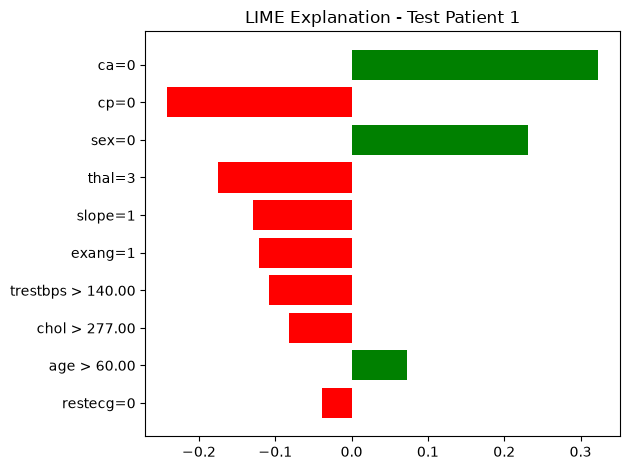

LIME analysis completed!


In [4]:
fig = explanation.as_pyplot_figure(label=1)

plt.title("LIME Explanation - Test Patient 1")
plt.tight_layout()

fig.savefig(
    OUT / "lime_patient1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

explanation.save_to_file(
    str(OUT / "lime_patient1.html")
)

print("LIME analysis completed!")